**Bài Tập Ở Lớp**

Độ chính xác của mô hình KNN với K=3: 1.00
Ma trận nhầm lẫn:
[[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]
Báo cáo phân loại:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      1.00      1.00         9
           2       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



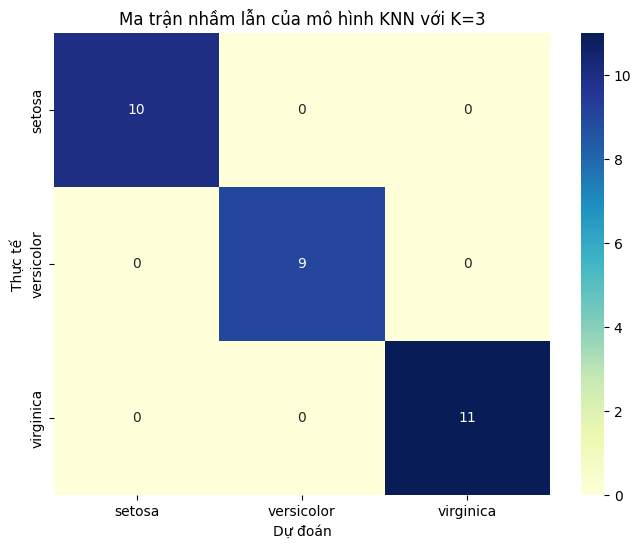

In [2]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report
import matplotlib.pyplot as plt
import seaborn as sns

iris = load_iris()
X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
k = 3
knn_model = KNeighborsClassifier(n_neighbors=k)
knn_model.fit(X_train, y_train)

y_pred = knn_model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
print(f"Độ chính xác của mô hình KNN với K={k}: {accuracy:.2f}")
print("Ma trận nhầm lẫn:")
print(conf_matrix)
print("Báo cáo phân loại:")
print(classification_report(y_test, y_pred))
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, cmap="YlGnBu", fmt="d",
xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.xlabel('Dự đoán')
plt.ylabel('Thực tế')
plt.title(f"Ma trận nhầm lẫn của mô hình KNN với K={k}")
plt.show()

Độ chính xác của mô hình SVM: 0.98
Ma trận nhầm lẫn:
[[41  2]
 [ 0 71]]
Báo cáo phân loại:
              precision    recall  f1-score   support

           0       1.00      0.95      0.98        43
           1       0.97      1.00      0.99        71

    accuracy                           0.98       114
   macro avg       0.99      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



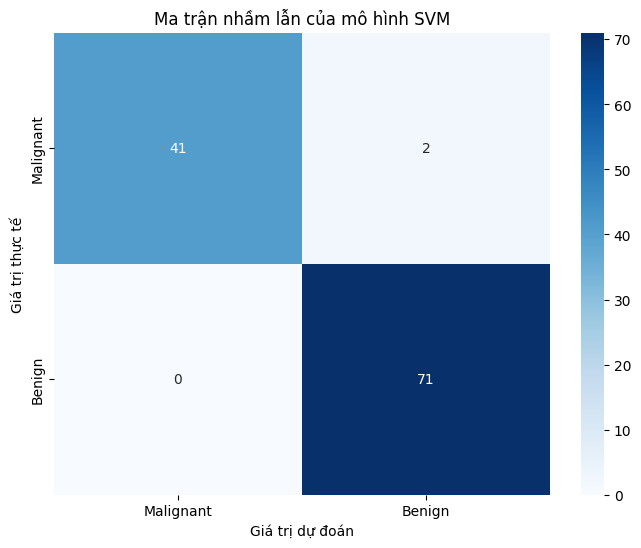

In [4]:
import numpy as np
import pandas as pd
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt
cancer = datasets.load_breast_cancer()
X = cancer.data
y = cancer.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,
random_state=42)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
svm_model = SVC(kernel='rbf', C=1, gamma='scale')
svm_model.fit(X_train, y_train)
# Dự đoán trên tập kiểm tra
y_pred = svm_model.predict(X_test)
# Đánh giá mô hình
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
print(f"Độ chính xác của mô hình SVM: {accuracy:.2f}")
print("Ma trận nhầm lẫn:")
print(conf_matrix)
print("Báo cáo phân loại:")
print(classification_report(y_test, y_pred))
# Trực quan hóa ma trận nhầm lẫn
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues",
xticklabels=['Malignant', 'Benign'], yticklabels=['Malignant', 'Benign'])

plt.xlabel("Giá trị dự đoán")
plt.ylabel("Giá trị thực tế")
plt.title("Ma trận nhầm lẫn của mô hình SVM")
plt.show()

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Tải dữ liệu Breast Cancer (các đặc trưng chênh lệch biên độ rất lớn: radius ~ 20, area ~ 2000)
data = load_breast_cancer()
X_train, X_test, y_train, y_test = train_test_split(
    data.data, data.target, test_size=0.2, random_state=42, stratify=data.target
)

# 2. So sánh nhanh trước và sau chuẩn hóa (với K=5 mặc định)
acc_raw = accuracy_score(y_test, KNeighborsClassifier(n_neighbors=5).fit(X_train, y_train).predict(X_test))

pipe_default = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier(n_neighbors=5))
])
acc_scaled = accuracy_score(y_test, pipe_default.fit(X_train, y_train).predict(X_test))

print(f"Độ chính xác TRƯỚC chuẩn hóa : {acc_raw * 100:.2f}%")
print(f"Độ chính xác SAU chuẩn hóa   : {acc_scaled * 100:.2f}%\n")

# 3. Dùng GridSearchCV kết hợp tìm K tối ưu (1..25) và so sánh độ đo khoảng cách
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier())
])

param_grid = {
    'knn__n_neighbors': list(range(1, 26, 2)),       # Yêu cầu 1: Thử các giá trị K lẻ từ 1 đến 25
    'knn__metric': ['manhattan', 'euclidean', 'minkowski'], # Yêu cầu 3: Các độ đo khoảng cách
    'knn__p': [1, 2, 3, 4]                           # Bậc p cho Minkowski (p=1: Manhattan, p=2: Euclidean)
}

grid = GridSearchCV(pipeline, param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid.fit(X_train, y_train)

print("--- KẾT QUẢ TỐI ƯU TỪ GRIDSEARCHCV ---")
print(f"Tham số tốt nhất : {grid.best_params_}")
print(f"CV Accuracy      : {grid.best_score_ * 100:.2f}%")

# Đánh giá mô hình tối ưu nhất trên tập Test
best_model = grid.best_estimator_
y_pred = best_model.predict(X_test)
print(f"Test Accuracy    : {accuracy_score(y_test, y_pred) * 100:.2f}%\n")
print("Báo cáo phân loại chi tiết:")
print(classification_report(y_test, y_pred, target_names=data.target_names))

Độ chính xác TRƯỚC chuẩn hóa : 91.23%
Độ chính xác SAU chuẩn hóa   : 95.61%

--- KẾT QUẢ TỐI ƯU TỪ GRIDSEARCHCV ---
Tham số tốt nhất : {'knn__metric': 'euclidean', 'knn__n_neighbors': 7, 'knn__p': 1}
CV Accuracy      : 97.14%
Test Accuracy    : 97.37%

Báo cáo phân loại chi tiết:
              precision    recall  f1-score   support

   malignant       1.00      0.93      0.96        42
      benign       0.96      1.00      0.98        72

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



--- BẢNG ĐÁNH GIÁ KNN REGRESSOR THEO CÁC GIÁ TRỊ K ---
 K     MSE  RMSE ($1,000)  R2 Score
 1 24.9096         4.9910    0.6603
 3 19.4043         4.4050    0.7354
 5 20.6055         4.5393    0.7190
 7 23.4155         4.8390    0.6807
 9 24.0094         4.8999    0.6726
11 24.6893         4.9688    0.6633
15 26.1870         5.1173    0.6429

-> Giá trị K tối ưu nhất: K = 3 với MSE = 19.4043 và R2 = 0.7354


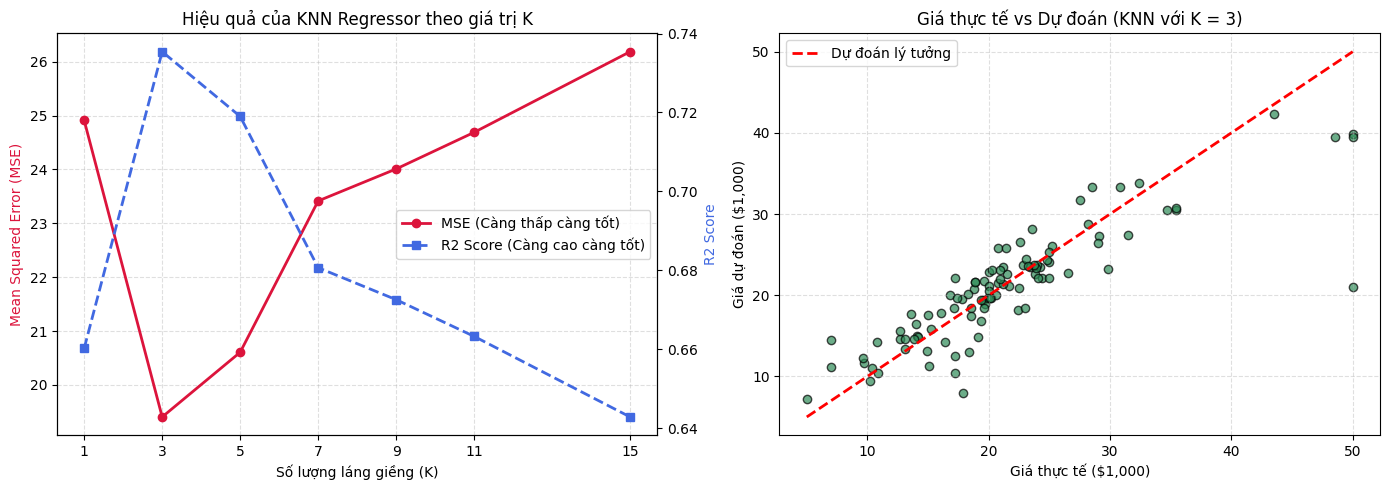

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, r2_score

# ==============================================================================
# 1. TẢI TẬP DỮ LIỆU BOSTON HOUSING
# ==============================================================================
boston = fetch_openml(name="boston", version=1, as_frame=True, parser="auto")
df = boston.frame.astype(float)

X = df.drop(columns=['MEDV'])  # 13 đặc trưng đầu vào
y = df['MEDV']                 # Biến mục tiêu: Giá nhà trung vị ($1,000)

# ==============================================================================
# 2. PHÂN CHIA DỮ LIỆU THÀNH TẬP HUẤN LUYỆN (80%) VÀ TẬP KIỂM TRA (20%)
# ==============================================================================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# ==============================================================================
# 3. CHUẨN HÓA DỮ LIỆU ĐỂ CÁC ĐẶC TRƯNG Ở CÙNG MỘT KHOẢNG GIÁ TRỊ
# ==============================================================================
# Bắt buộc với KNN vì khoảng cách Euclidean sẽ bị áp đảo bởi các cột có đơn vị lớn (như TAX, B)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# ==============================================================================
# 4 & 5. ÁP DỤNG KNN REGRESSOR VỚI CÁC GIÁ TRỊ K KHÁC NHAU & ĐÁNH GIÁ (MSE, R2)
# ==============================================================================
k_values = [1, 3, 5, 7, 9, 11, 15]
results = []

for k in k_values:
    # Khởi tạo và huấn luyện mô hình hồi quy KNN
    knn_reg = KNeighborsRegressor(n_neighbors=k)
    knn_reg.fit(X_train_scaled, y_train)

    # Dự đoán trên tập kiểm tra
    y_pred = knn_reg.predict(X_test_scaled)

    # Tính các chỉ số đánh giá
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    results.append({
        'K': k,
        'MSE': round(mse, 4),
        'RMSE ($1,000)': round(rmse, 4),
        'R2 Score': round(r2, 4)
    })

results_df = pd.DataFrame(results)
print("--- BẢNG ĐÁNH GIÁ KNN REGRESSOR THEO CÁC GIÁ TRỊ K ---")
print(results_df.to_string(index=False))

# Xác định K tốt nhất trên tập kiểm tra
best_row = results_df.loc[results_df['R2 Score'].idxmax()]
print(f"\n-> Giá trị K tối ưu nhất: K = {int(best_row['K'])} với MSE = {best_row['MSE']} và R2 = {best_row['R2 Score']}")

# ==============================================================================
# TRỰC QUAN HÓA KẾT QUẢ THỰC NGHIỆM
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Biểu đồ 1: Sự thay đổi của MSE và R2 theo K
ax1 = axes[0]
ax1_twin = ax1.twinx()

p1 = ax1.plot(results_df['K'], results_df['MSE'], marker='o', color='crimson', linewidth=2, label='MSE (Càng thấp càng tốt)')
p2 = ax1_twin.plot(results_df['K'], results_df['R2 Score'], marker='s', color='royalblue', linewidth=2, linestyle='--', label='R2 Score (Càng cao càng tốt)')

ax1.set_title('Hiệu quả của KNN Regressor theo giá trị K')
ax1.set_xlabel('Số lượng láng giềng (K)')
ax1.set_ylabel('Mean Squared Error (MSE)', color='crimson')
ax1_twin.set_ylabel('R2 Score', color='royalblue')
ax1.set_xticks(k_values)
ax1.grid(True, linestyle='--', alpha=0.4)

# Gộp chú thích (legend) cho 2 trục tung
lines = p1 + p2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='center right')

# Biểu đồ 2: Đối chiếu Giá thực tế vs Giá dự đoán tại K tối ưu
best_k = int(best_row['K'])
best_knn = KNeighborsRegressor(n_neighbors=best_k).fit(X_train_scaled, y_train)
y_pred_best = best_knn.predict(X_test_scaled)

axes[1].scatter(y_test, y_pred_best, alpha=0.7, color='seagreen', edgecolors='k')
axes[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Dự đoán lý tưởng')
axes[1].set_title(f'Giá thực tế vs Dự đoán (KNN với K = {best_k})')
axes[1].set_xlabel('Giá thực tế ($1,000)')
axes[1].set_ylabel('Giá dự đoán ($1,000)')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

--- THÔNG TIN BỘ DỮ LIỆU IRIS ---
Tổng số mẫu: 150 | Số đặc trưng: 4 | Số lớp: 3
Phân bố các lớp: {np.str_('setosa'): np.int64(50), np.str_('versicolor'): np.int64(50), np.str_('virginica'): np.int64(50)}

--- KẾT QUẢ THỰC NGHIỆM 1: SO SÁNH CÁC TỶ LỆ CHIA HOLD-OUT ---
   Cách chia dữ liệu  Số mẫu Train  Số mẫu Test  Accuracy (%)  Precision (Macro)  Recall (Macro)  F1-Score (Macro)
Train 90% - Test 10%           135           15         93.33             0.9444          0.9333            0.9327
Train 80% - Test 20%           120           30         96.67             0.9697          0.9667            0.9666
Train 70% - Test 30%           105           45         93.33             0.9345          0.9333            0.9333
Train 60% - Test 40%            90           60         95.00             0.9507          0.9500            0.9500
Train 50% - Test 50%            75           75         96.00             0.9605          0.9600            0.9600 

--- KẾT QUẢ THỰC NGHIỆM 2: ĐÁNH GIÁ BẰN

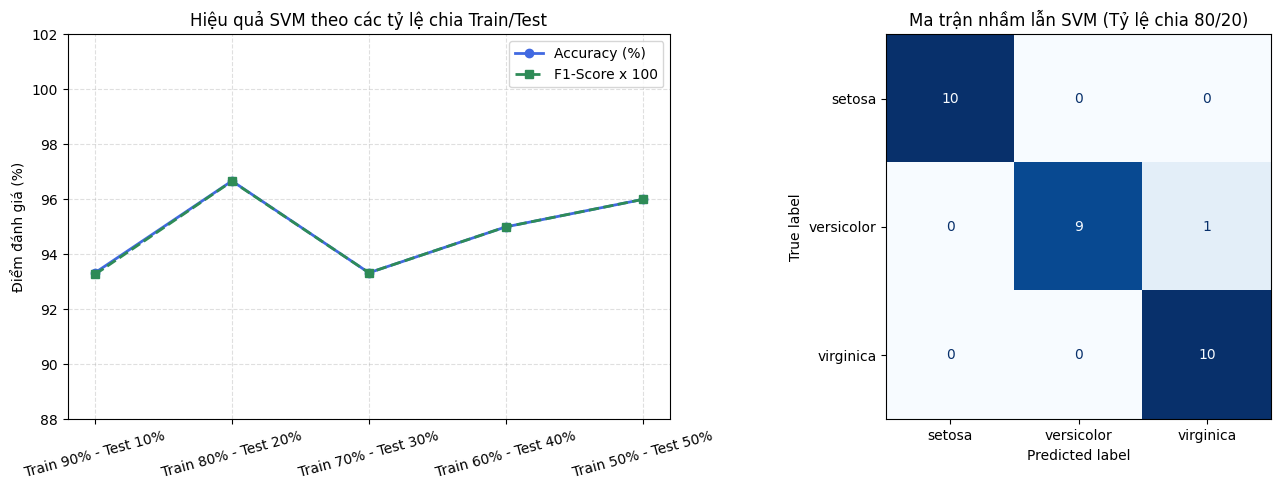

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
)

# ==============================================================================
# 1. TẢI DỮ LIỆU IRIS & THIẾT LẬP PIPELINE SVM
# ==============================================================================
iris = load_iris()
X = pd.DataFrame(iris.data, columns=iris.feature_names)
y = iris.target
target_names = iris.target_names

print("--- THÔNG TIN BỘ DỮ LIỆU IRIS ---")
print(f"Tổng số mẫu: {X.shape[0]} | Số đặc trưng: {X.shape[1]} | Số lớp: {len(target_names)}")
print(f"Phân bố các lớp: {dict(zip(target_names, np.bincount(y)))}\n")

# Sử dụng Pipeline gồm StandardScaler (bắt buộc cho SVM) + SVC (RBF Kernel)
def create_svm_pipeline(kernel='rbf', C=1.0):
    return Pipeline([
        ('scaler', StandardScaler()),
        ('svm', SVC(kernel=kernel, C=C, gamma='scale', random_state=42))
    ])

# ==============================================================================
# 2. THỰC NGHIỆM 1: SO SÁNH CÁC TỶ LỆ CHIA HOLD-OUT KHÁC NHAU (STRATIFIED)
# ==============================================================================
split_configs = [
    ("Train 90% - Test 10%", 0.10),
    ("Train 80% - Test 20%", 0.20),
    ("Train 70% - Test 30%", 0.30),
    ("Train 60% - Test 40%", 0.40),
    ("Train 50% - Test 50%", 0.50),
]

holdout_results = []

for label, test_sz in split_configs:
    # Chia phân tầng (stratify=y) để giữ nguyên tỷ lệ 1:1:1 giữa 3 loài hoa
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_sz, random_state=42, stratify=y
    )

    model = create_svm_pipeline(kernel='rbf', C=1.0)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    holdout_results.append({
        'Cách chia dữ liệu': label,
        'Số mẫu Train': len(X_train),
        'Số mẫu Test': len(X_test),
        'Accuracy (%)': round(accuracy_score(y_test, y_pred) * 100, 2),
        'Precision (Macro)': round(precision_score(y_test, y_pred, average='macro'), 4),
        'Recall (Macro)': round(recall_score(y_test, y_pred, average='macro'), 4),
        'F1-Score (Macro)': round(f1_score(y_test, y_pred, average='macro'), 4)
    })

df_holdout = pd.DataFrame(holdout_results)
print("--- KẾT QUẢ THỰC NGHIỆM 1: SO SÁNH CÁC TỶ LỆ CHIA HOLD-OUT ---")
print(df_holdout.to_string(index=False), "\n")

# ==============================================================================
# 3. THỰC NGHIỆM 2: KIỂM ĐỊNH CHÉO K-FOLD CROSS-VALIDATION (K=5 VÀ K=10)
# ==============================================================================
# Giúp đánh giá độ ổn định (Mean ± Std) thay vì phụ thuộc vào 1 lần chia ngẫu nhiên
cv_results = []
for k_folds in [5, 10]:
    skf = StratifiedKFold(n_splits=k_folds, shuffle=True, random_state=42)
    model = create_svm_pipeline(kernel='rbf', C=1.0)

    scores = cross_validate(
        model, X, y, cv=skf,
        scoring=['accuracy', 'precision_macro', 'recall_macro', 'f1_macro']
    )

    cv_results.append({
        'Phương pháp CV': f'Stratified {k_folds}-Fold CV',
        'Accuracy TB (%)': f"{scores['test_accuracy'].mean()*100:.2f} ± {scores['test_accuracy'].std()*100:.2f}",
        'Precision TB': round(scores['test_precision_macro'].mean(), 4),
        'Recall TB': round(scores['test_recall_macro'].mean(), 4),
        'F1-Score TB': round(scores['test_f1_macro'].mean(), 4)
    })

df_cv = pd.DataFrame(cv_results)
print("--- KẾT QUẢ THỰC NGHIỆM 2: ĐÁNH GIÁ BẰNG STRATIFIED K-FOLD CV ---")
print(df_cv.to_string(index=False), "\n")

# ==============================================================================
# 4. THỰC NGHIỆM 3: SO SÁNH CHIA CÓ PHÂN TẦNG (STRATIFY) VS KHÔNG PHÂN TẦNG
# ==============================================================================
# Thử lặp qua 50 hạt giống ngẫu nhiên (random_state) ở tỷ lệ 80/20 để thấy sự ổn định
acc_no_strat, acc_strat = [], []
for seed in range(50):
    # Không dùng stratify
    X_tr1, X_te1, y_tr1, y_te1 = train_test_split(X, y, test_size=0.2, random_state=seed, stratify=None)
    m1 = create_svm_pipeline().fit(X_tr1, y_tr1)
    acc_no_strat.append(accuracy_score(y_te1, m1.predict(X_te1)))

    # Có dùng stratify=y
    X_tr2, X_te2, y_tr2, y_te2 = train_test_split(X, y, test_size=0.2, random_state=seed, stratify=y)
    m2 = create_svm_pipeline().fit(X_tr2, y_tr2)
    acc_strat.append(accuracy_score(y_te2, m2.predict(X_te2)))

print("--- KẾT QUẢ THỰC NGHIỆM 3: ĐỘ ỔN ĐỊNH QUA 50 LẦN CHIA NGẪU NHIÊN (TỶ LỆ 80/20) ---")
print(f"Không dùng Stratify : Mean = {np.mean(acc_no_strat)*100:.2f}% | Độ lệch chuẩn (Std) = {np.std(acc_no_strat)*100:.2f}% | Min = {np.min(acc_no_strat)*100:.2f}%")
print(f"Có dùng Stratify=y  : Mean = {np.mean(acc_strat)*100:.2f}% | Độ lệch chuẩn (Std) = {np.std(acc_strat)*100:.2f}% | Min = {np.min(acc_strat)*100:.2f}%\n")

# ==============================================================================
# 5. TRỰC QUAN HÓA SO SÁNH & MA TRẬN NHẦM LẪN (TẠI TỶ LỆ CHUẨN 80/20)
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Biểu đồ 1: So sánh Accuracy và F1-Score giữa các tỷ lệ chia Hold-out
x_pos = np.arange(len(df_holdout))
axes[0].plot(df_holdout['Cách chia dữ liệu'], df_holdout['Accuracy (%)'], marker='o', linewidth=2, color='royalblue', label='Accuracy (%)')
axes[0].plot(df_holdout['Cách chia dữ liệu'], df_holdout['F1-Score (Macro)'] * 100, marker='s', linestyle='--', linewidth=2, color='seagreen', label='F1-Score x 100')
axes[0].set_title('Hiệu quả SVM theo các tỷ lệ chia Train/Test')
axes[0].set_ylabel('Điểm đánh giá (%)')
axes[0].set_ylim(88, 102)
axes[0].tick_params(axis='x', rotation=15)
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.4)

# Biểu đồ 2: Ma trận nhầm lẫn của mô hình SVM tại tỷ lệ chia 80/20
X_tr_80, X_te_80, y_tr_80, y_te_80 = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
best_svm = create_svm_pipeline().fit(X_tr_80, y_tr_80)
cm = confusion_matrix(y_te_80, best_svm.predict(X_te_80))

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=target_names)
disp.plot(ax=axes[1], cmap='Blues', colorbar=False)
axes[1].set_title('Ma trận nhầm lẫn SVM (Tỷ lệ chia 80/20)')

plt.tight_layout()
plt.show()

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# ==============================================================================
# 1. TẢI TẬP DỮ LIỆU BOSTON HOUSING & PHÂN CHIA TRAIN / TEST
# ==============================================================================
boston = fetch_openml(name="boston", version=1, as_frame=True, parser="auto")
df = boston.frame.astype(float)

X = df.drop(columns=['MEDV'])  # 13 đặc trưng đầu vào
y = df['MEDV']                 # Giá nhà trung vị ($1,000)

# Giữ nguyên random_state=42 và test_size=0.2 như Bài 2 để so sánh công bằng
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# ==============================================================================
# 2. CHUẨN HÓA DỮ LIỆU (BẮT BUỘC VỚI SVR)
# ==============================================================================
# SVR tối ưu khoảng cách hình học và tính tích vô hướng/khoảng cách Euclid trong không gian kernel,
# nên nếu không chuẩn hóa, các biến có biên độ lớn (TAX, B) sẽ phá hỏng siêu phẳng hồi quy.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# ==============================================================================
# 3. HUẤN LUYỆN MÔ HÌNH SVR VỚI KERNEL 'LINEAR' VÀ 'RBF'
# ==============================================================================
# Khởi tạo các cấu hình SVR (bao gồm mặc định và tinh chỉnh C để thấy rõ sức mạnh của RBF)
svr_configs = [
    ("SVR (kernel='linear', C=1.0)",  SVR(kernel='linear', C=1.0, epsilon=0.1)),
    ("SVR (kernel='rbf', C=1.0)",     SVR(kernel='rbf', C=1.0, gamma='scale', epsilon=0.1)),
    ("SVR (kernel='rbf', C=10.0)",    SVR(kernel='rbf', C=10.0, gamma='scale', epsilon=0.1)),
    ("SVR (kernel='rbf', C=50.0)",    SVR(kernel='rbf', C=50.0, gamma='scale', epsilon=0.1)),
]

results = []
predictions = {}

for name, model in svr_configs:
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    predictions[name] = y_pred

    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    results.append({
        'Mô hình': name,
        'MSE': round(mse, 4),
        'RMSE ($1,000)': round(rmse, 4),
        'MAE ($1,000)': round(mae, 4),
        'R2 Score': round(r2, 4)
    })

results_df = pd.DataFrame(results)
print("--- BẢNG SO SÁNH HIỆU QUẢ CỦA SVR TRÊN BOSTON HOUSING ---")
print(results_df.to_string(index=False))

# ==============================================================================
# 4. TỐI ƯU SIÊU THAM SỐ TỰ ĐỘNG BẰNG GRIDSEARCHCV CHO SVR (RBF)
# ==============================================================================
param_grid = {
    'C': [1, 10, 50, 100],
    'gamma': ['scale', 0.01, 0.05, 0.1],
    'epsilon': [0.1, 0.5, 1.0]
}
grid_svr = GridSearchCV(SVR(kernel='rbf'), param_grid, cv=5, scoring='r2', n_jobs=-1)
grid_svr.fit(X_train_scaled, y_train)

y_pred_best = grid_svr

--- BẢNG SO SÁNH HIỆU QUẢ CỦA SVR TRÊN BOSTON HOUSING ---
                     Mô hình     MSE  RMSE ($1,000)  MAE ($1,000)  R2 Score
SVR (kernel='linear', C=1.0) 28.9185         5.3776        3.1036    0.6057
   SVR (kernel='rbf', C=1.0) 25.6685         5.0664        2.7317    0.6500
  SVR (kernel='rbf', C=10.0) 12.7382         3.5691        2.0657    0.8263
  SVR (kernel='rbf', C=50.0) 11.3248         3.3652        2.0090    0.8456


**Bài tập về nhà**


--- BẢNG SO SÁNH HIỆU SUẤT CÁC KERNEL TRONG SVM ---
              Loại Kernel  Số Support Vectors  CV Acc (%)  Test Acc (%)  Precision  Recall  F1-Score  Thời gian (ms)
      Linear (Tuyến tính)                  32       96.70         97.37     0.9859  0.9722    0.9790            6.68
       Polynomial (Bậc 2)                  58       97.80         98.25     0.9861  0.9861    0.9861           12.26
       Polynomial (Bậc 3)                  54       97.58         97.37     0.9859  0.9722    0.9790            5.75
       Polynomial (Bậc 4)                  56       97.80         97.37     0.9859  0.9722    0.9790            6.26
RBF (Gaussian - Mặc định)                  97       97.14         98.25     0.9861  0.9861    0.9861            8.00
                  Sigmoid                  66       96.92         92.98     0.9571  0.9306    0.9437           14.84


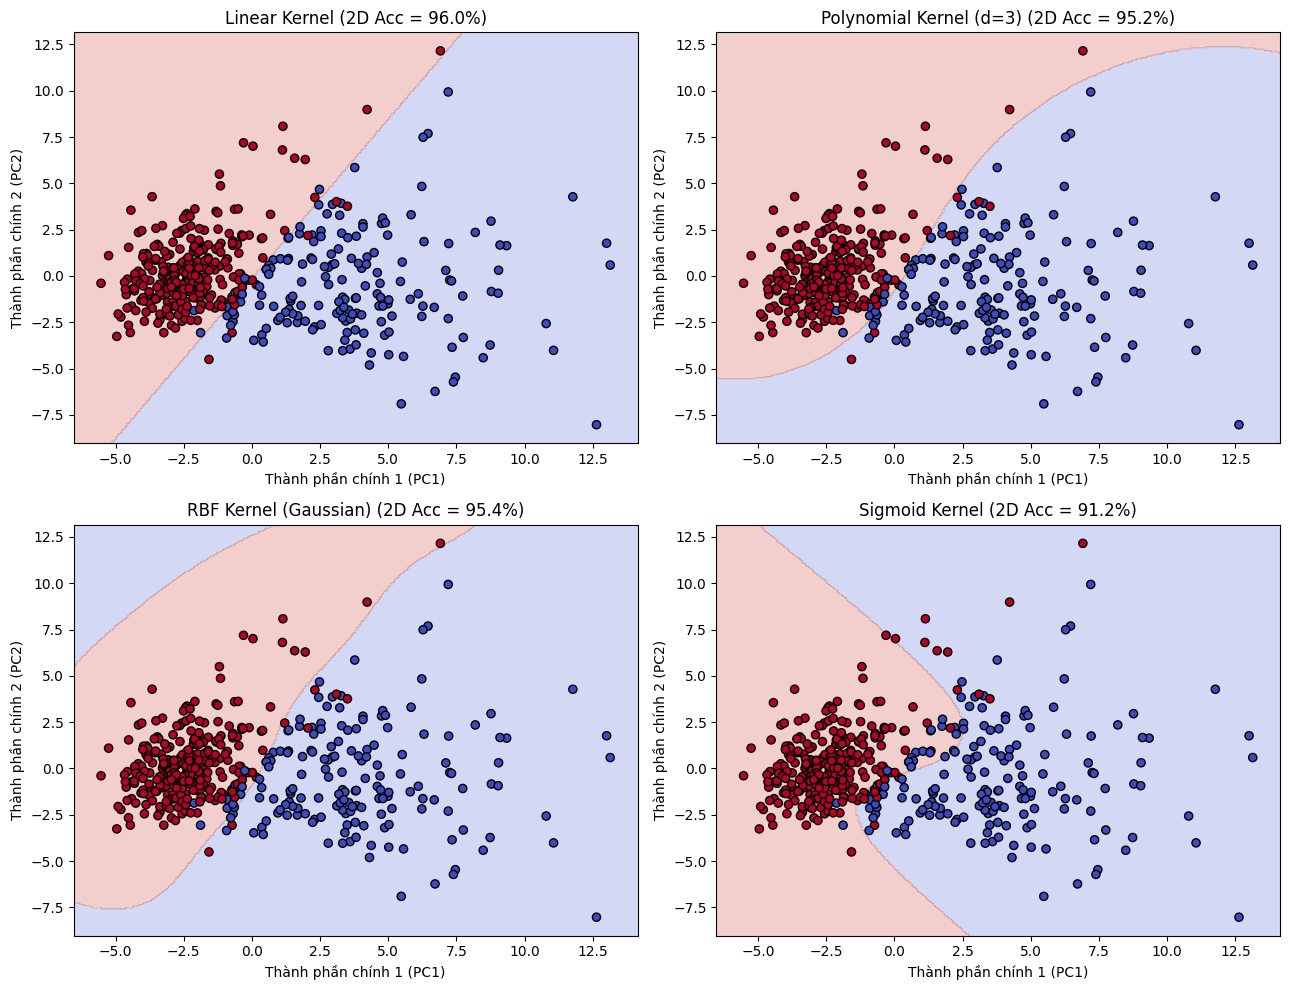

In [9]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# ==============================================================================
# 1. TẢI DỮ LIỆU & TIỀN XỬ LÝ (CHUẨN HÓA)
# ==============================================================================
data = load_breast_cancer()
X, y = data.data, data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Chuẩn hóa đặc trưng (bắt buộc với SVM để các kernel tính khoảng cách/tích vô hướng chính xác)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# ==============================================================================
# 2. THỰC NGHIỆM SO SÁNH HIỆU SUẤT CÁC LOẠI KERNEL KHÁC NHAU
# ==============================================================================
kernel_configs = [
    ("Linear (Tuyến tính)",       {"kernel": "linear", "C": 1.0}),
    ("Polynomial (Bậc 2)",        {"kernel": "poly",   "degree": 2, "C": 1.0, "coef0": 1}),
    ("Polynomial (Bậc 3)",        {"kernel": "poly",   "degree": 3, "C": 1.0, "coef0": 1}),
    ("Polynomial (Bậc 4)",        {"kernel": "poly",   "degree": 4, "C": 1.0, "coef0": 1}),
    ("RBF (Gaussian - Mặc định)", {"kernel": "rbf",    "C": 1.0, "gamma": "scale"}),
    ("Sigmoid",                   {"kernel": "sigmoid","C": 1.0, "gamma": "scale"}),
]

results = []

for name, params in kernel_configs:
    model = SVC(**params, random_state=42)

    # Đánh giá 5-Fold Cross-Validation trên tập Train
    cv_acc = cross_val_score(model, X_train_scaled, y_train, cv=5, scoring='accuracy').mean()

    # Đo thời gian huấn luyện và đánh giá trên tập Test
    start_time = time.time()
    model.fit(X_train_scaled, y_train)
    train_time = (time.time() - start_time) * 1000  # đổi sang mili-giây (ms)

    y_pred = model.predict(X_test_scaled)

    results.append({
        "Loại Kernel": name,
        "Số Support Vectors": model.n_support_.sum(),
        "CV Acc (%)": round(cv_acc * 100, 2),
        "Test Acc (%)": round(accuracy_score(y_test, y_pred) * 100, 2),
        "Precision": round(precision_score(y_test, y_pred), 4),
        "Recall": round(recall_score(y_test, y_pred), 4),
        "F1-Score": round(f1_score(y_test, y_pred), 4),
        "Thời gian (ms)": round(train_time, 2)
    })

results_df = pd.DataFrame(results)
print("--- BẢNG SO SÁNH HIỆU SUẤT CÁC KERNEL TRONG SVM ---")
print(results_df.to_string(index=False))

# ==============================================================================
# 3. TRỰC QUAN HÓA RANH GIỚI QUYẾT ĐỊNH (DECISION BOUNDARY) CỦA 4 KERNEL TIÊU BIỂU
# ==============================================================================
# Giảm chiều dữ liệu xuống 2 thành phần chính (PCA) để vẽ hình dạng đường biên phân lớp
pca = PCA(n_components=2)
X_train_2d = pca.fit_transform(X_train_scaled)

plot_kernels = [
    ("Linear Kernel",          SVC(kernel='linear', C=1.0)),
    ("Polynomial Kernel (d=3)",SVC(kernel='poly', degree=3, C=1.0, coef0=1)),
    ("RBF Kernel (Gaussian)",  SVC(kernel='rbf', C=1.0, gamma='scale')),
    ("Sigmoid Kernel",         SVC(kernel='sigmoid', C=1.0, gamma='scale')),
]

# Tạo lưới tọa độ để tô màu vùng quyết định
x_min, x_max = X_train_2d[:, 0].min() - 1, X_train_2d[:, 0].max() + 1
y_min, y_max = X_train_2d[:, 1].min() - 1, X_train_2d[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
axes = axes.ravel()

for idx, (title, clf) in enumerate(plot_kernels):
    clf.fit(X_train_2d, y_train)
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

    axes[idx].contourf(xx, yy, Z, alpha=0.25, cmap=plt.cm.coolwarm)
    axes[idx].scatter(X_train_2d[:, 0], X_train_2d[:, 1], c=y_train, cmap=plt.cm.coolwarm, edgecolors='k', s=35)
    axes[idx].set_title(f"{title} (2D Acc = {clf.score(X_train_2d, y_train)*100:.1f}%)")
    axes[idx].set_xlabel("Thành phần chính 1 (PC1)")
    axes[idx].set_ylabel("Thành phần chính 2 (PC2)")

plt.tight_layout()
plt.show()

--- KẾT QUẢ TÌM KIẾM SIÊU THAM SỐ BẰNG GRIDSEARCHCV ---
Tổng số tổ hợp tham số đã thử : 48
Bộ siêu tham số tốt nhất      : {'svm__C': 10, 'svm__gamma': 0.01, 'svm__kernel': 'rbf'}
Độ chính xác CV tốt nhất      : 98.02%

--- SO SÁNH HIỆU QUẢ TRÊN TẬP KIỂM TRA (TEST SET) ---
1. SVM Mặc định (C=1.0, rbf, scale) : 98.25%
2. SVM Sau tối ưu GridSearchCV      : 98.25%

Báo cáo phân loại chi tiết của mô hình tối ưu:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114

--- TOP 5 CẤU HÌNH SIÊU THAM SỐ TỐT NHẤT ---
 rank_test_score                                                     params  mean_train_score  mean_test_score  std_test_score
               1   {'svm__C': 10, 'svm__gamma': 0.01, 'svm__kernel': 'rbf'}          0.98

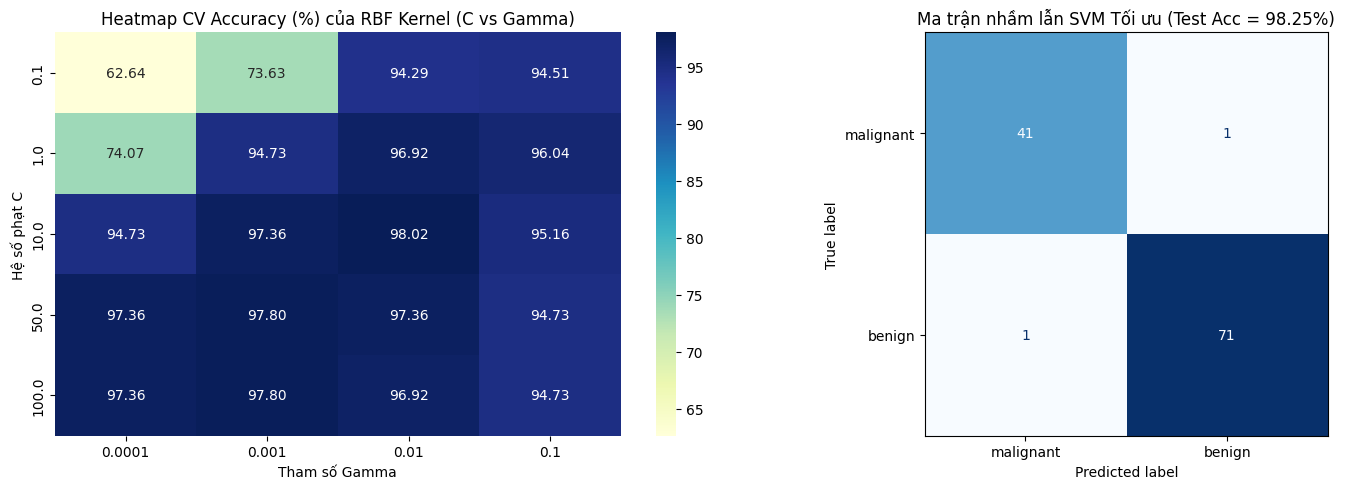

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
)

# ==============================================================================
# 1. TẢI DỮ LIỆU & CHIA TẬP TRAIN (80%) - TEST (20%)
# ==============================================================================
data = load_breast_cancer()
X_train, X_test, y_train, y_test = train_test_split(
    data.data, data.target, test_size=0.2, random_state=42, stratify=data.target
)

# Đánh giá mô hình SVM mặc định (Baseline) trước khi tối ưu để làm mốc so sánh
baseline_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(random_state=42))
])
baseline_pipe.fit(X_train, y_train)
baseline_acc = accuracy_score(y_test, baseline_pipe.predict(X_test))

# ==============================================================================
# 2. THIẾT LẬP PIPELINE & KHÔNG GIAN LƯỚI SIÊU THAM SỐ (PARAM_GRID)
# ==============================================================================
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(random_state=42))
])

# Sử dụng danh sách các từ điển (list of dicts) để chỉ ghép cặp tham số hợp lệ cho từng kernel
# (Ví dụ: kernel 'linear' không cần thử nhiều giá trị 'gamma', giúp tiết kiệm thời gian chạy)
param_grid = [
    {
        'svm__kernel': ['linear'],
        'svm__C': [0.01, 0.1, 1, 10, 100]
    },
    {
        'svm__kernel': ['rbf'],
        'svm__C': [0.1, 1, 10, 50, 100],
        'svm__gamma': ['scale', 0.1, 0.01, 0.001, 0.0001]
    },
    {
        'svm__kernel': ['poly'],
        'svm__degree': [2, 3],
        'svm__C': [0.1, 1, 10],
        'svm__gamma': ['scale', 0.01, 0.001]
    }
]

# ==============================================================================
# 3. KHỞI TẠO VÀ CHẠY GRIDSEARCHCV (5-FOLD CROSS-VALIDATION)
# ==============================================================================
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=5,                  # Chia tập Train thành 5 phần đánh giá chéo
    scoring='accuracy',    # Thước đo tối ưu (có thể đổi thành 'f1' hoặc 'recall' cho y tế)
    n_jobs=-1,             # Sử dụng toàn bộ nhân CPU để chạy song song
    return_train_score=True
)

grid_search.fit(X_train, y_train)

# ==============================================================================
# 4. TRÍCH XUẤT KẾT QUẢ TỐI ƯU & ĐÁNH GIÁ TRÊN TẬP TEST
# ==============================================================================
print("--- KẾT QUẢ TÌM KIẾM SIÊU THAM SỐ BẰNG GRIDSEARCHCV ---")
print(f"Tổng số tổ hợp tham số đã thử : {len(grid_search.cv_results_['params'])}")
print(f"Bộ siêu tham số tốt nhất      : {grid_search.best_params_}")
print(f"Độ chính xác CV tốt nhất      : {grid_search.best_score_ * 100:.2f}%\n")

# Lấy mô hình tốt nhất đã được huấn luyện lại trên toàn bộ tập Train (refit=True mặc định)
best_svm_model = grid_search.best_estimator_
y_pred_best = best_svm_model.predict(X_test)
best_test_acc = accuracy_score(y_test, y_pred_best)

print("--- SO SÁNH HIỆU QUẢ TRÊN TẬP KIỂM TRA (TEST SET) ---")
print(f"1. SVM Mặc định (C=1.0, rbf, scale) : {baseline_acc * 100:.2f}%")
print(f"2. SVM Sau tối ưu GridSearchCV      : {best_test_acc * 100:.2f}%\n")

print("Báo cáo phân loại chi tiết của mô hình tối ưu:")
print(classification_report(y_test, y_pred_best, target_names=data.target_names))

# Hiển thị Top 5 cấu hình có điểm CV cao nhất
cv_results_df = pd.DataFrame(grid_search.cv_results_)
top5 = cv_results_df.sort_values(by='rank_test_score')[
    ['rank_test_score', 'params', 'mean_train_score', 'mean_test_score', 'std_test_score']
].head(5)
print("--- TOP 5 CẤU HÌNH SIÊU THAM SỐ TỐT NHẤT ---")
print(top5.to_string(index=False))

# ==============================================================================
# 5. TRỰC QUAN HÓA HEATMAP (C VS GAMMA CHO RBF KERNEL) & MA TRẬN NHẦM LẪN
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Biểu đồ 1: Heatmap điểm CV Accuracy của tổ hợp (C, gamma) trên RBF Kernel
rbf_results = cv_results_df[
    (cv_results_df['param_svm__kernel'] == 'rbf') &
    (cv_results_df['param_svm__gamma'] != 'scale')
].copy()

pivot_table = rbf_results.pivot(
    index='param_svm__C',
    columns='param_svm__gamma',
    values='mean_test_score'
) * 100

sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap="YlGnBu", ax=axes[0])
axes[0].set_title("Heatmap CV Accuracy (%) của RBF Kernel (C vs Gamma)")
axes[0].set_xlabel("Tham số Gamma")
axes[0].set_ylabel("Hệ số phạt C")

# Biểu đồ 2: Ma trận nhầm lẫn trên tập Test của mô hình tốt nhất
cm = confusion_matrix(y_test, y_pred_best)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=data.target_names)
disp.plot(ax=axes[1], cmap='Blues', colorbar=False)
axes[1].set_title(f"Ma trận nhầm lẫn SVM Tối ưu (Test Acc = {best_test_acc*100:.2f}%)")

plt.tight_layout()
plt.show()

--- 1. THÔNG TIN BỘ DỮ LIỆU DIGITS ---
Số lượng mẫu ảnh : 1797 | Số chiều đặc trưng (8x8 pixel): 64
Các nhãn chữ số  : [0 1 2 3 4 5 6 7 8 9]

--- 4. BẢNG SO SÁNH HIỆU QUẢ CÁC MÔ HÌNH TRÊN TẬP TEST ---
                  Mô hình  Accuracy (%)  Precision (Macro)  Recall (Macro)  F1-Score (Macro)  Thời gian Fit (ms)
     KNN (K=5, Euclidean)         96.39             0.9646          0.9637            0.9634               12.22
 SVM (kernel='poly', d=3)         99.17             0.9917          0.9916            0.9916              193.44
SVM (kernel='rbf', C=1.0)         97.50             0.9760          0.9748            0.9748              301.45
SVM (kernel='rbf', C=5.0)         98.06             0.9811          0.9804            0.9805              250.15 

Báo cáo phân loại chi tiết của mô hình tốt nhất (SVM (kernel='poly', d=3)):
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        36
           1       0.97      0.97      0.97    

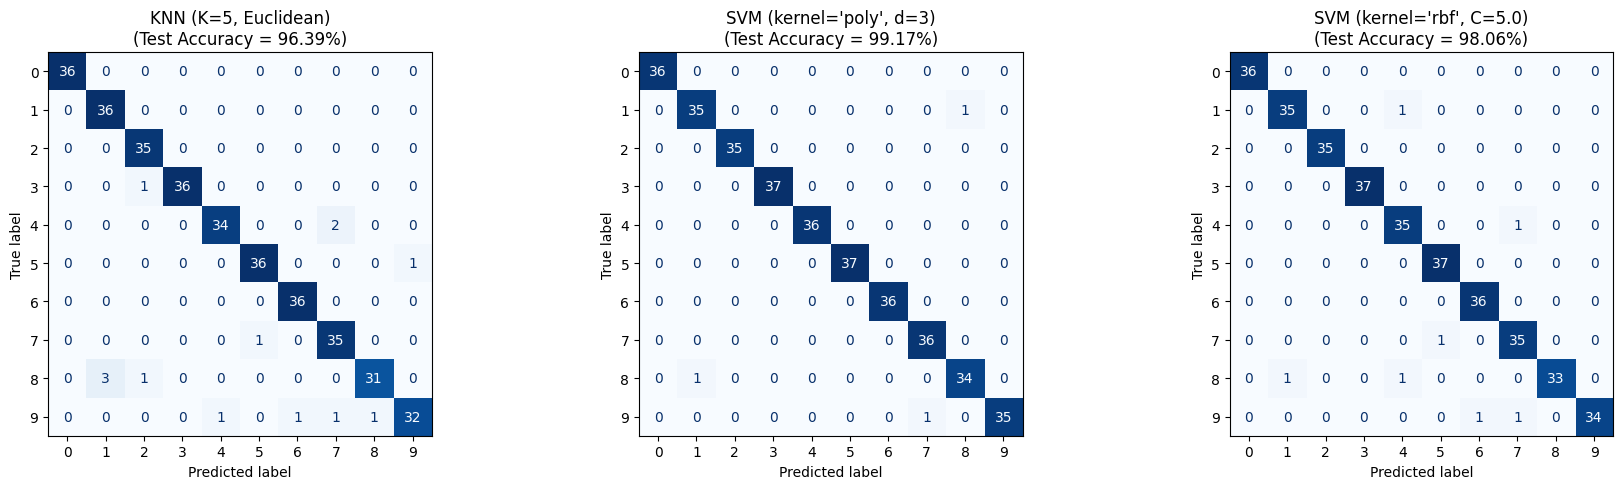

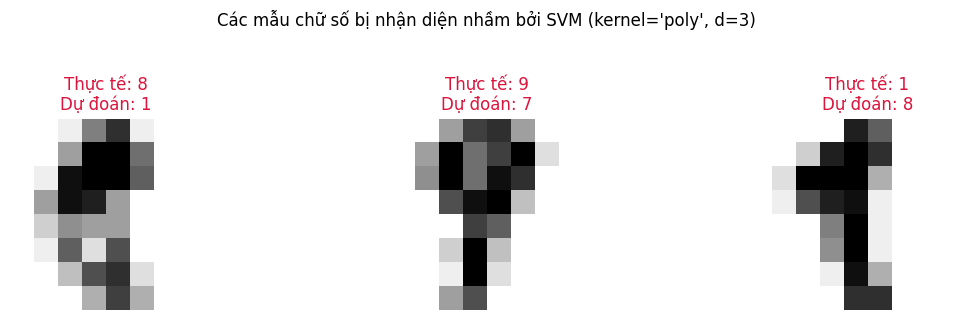

In [11]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
)

# ==============================================================================
# 1. TẢI TẬP DỮ LIỆU DIGITS TỪ SKLEARN.DATASETS
# ==============================================================================
digits = load_digits()
X = digits.data    # Ma trận đặc trưng (1797 mẫu x 64 pixel)
y = digits.target  # Nhãn chữ số từ 0 đến 9

print("--- 1. THÔNG TIN BỘ DỮ LIỆU DIGITS ---")
print(f"Số lượng mẫu ảnh : {X.shape[0]} | Số chiều đặc trưng (8x8 pixel): {X.shape[1]}")
print(f"Các nhãn chữ số  : {np.unique(y)}\n")

# ==============================================================================
# 2. PHÂN CHIA TẬP TRAIN (80%) - TEST (20%) VÀ CHUẨN HÓA DỮ LIỆU
# ==============================================================================
# Chia trước, chuẩn hóa sau để tránh rò rỉ dữ liệu (Data Leakage)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Lưu ý: Trong Digits có một số pixel ở viền ảnh luôn bằng 0 (phương sai = 0),
# StandardScaler tự động xử lý an toàn bằng cách giữ nguyên giá trị 0 cho các cột này.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# ==============================================================================
# 3. HUẤN LUYỆN LẦN LƯỢT MÔ HÌNH KNN, SVM (POLY) VÀ SVM (RBF)
# ==============================================================================
models = [
    ("KNN (K=5, Euclidean)",       KNeighborsClassifier(n_neighbors=5, metric='euclidean')),
    ("SVM (kernel='poly', d=3)",   SVC(kernel='poly', degree=3, C=1.0, coef0=1, random_state=42)),
    ("SVM (kernel='rbf', C=1.0)",  SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42)),
    ("SVM (kernel='rbf', C=5.0)",  SVC(kernel='rbf', C=5.0, gamma='scale', random_state=42))
]

results = []
trained_models = {}

for name, model in models:
    # Đo thời gian huấn luyện
    t0 = time.time()
    model.fit(X_train_scaled, y_train)
    train_ms = (time.time() - t0) * 1000

    # Dự đoán trên tập kiểm tra
    y_pred = model.predict(X_test_scaled)
    trained_models[name] = (model, y_pred)

    results.append({
        "Mô hình": name,
        "Accuracy (%)": round(accuracy_score(y_test, y_pred) * 100, 2),
        "Precision (Macro)": round(precision_score(y_test, y_pred, average='macro'), 4),
        "Recall (Macro)": round(recall_score(y_test, y_pred, average='macro'), 4),
        "F1-Score (Macro)": round(f1_score(y_test, y_pred, average='macro'), 4),
        "Thời gian Fit (ms)": round(train_ms, 2)
    })

# ==============================================================================
# 4. SO SÁNH ĐỘ CHÍNH XÁC VÀ HIỂN THỊ MA TRẬN NHẦM LẪN (CONFUSION MATRIX)
# ==============================================================================
results_df = pd.DataFrame(results)
print("--- 4. BẢNG SO SÁNH HIỆU QUẢ CÁC MÔ HÌNH TRÊN TẬP TEST ---")
print(results_df.to_string(index=False), "\n")

# In báo cáo phân loại chi tiết cho mô hình đạt điểm cao nhất
best_model_name = results_df.loc[results_df['Accuracy (%)'].idxmax(), 'Mô hình']
_, best_y_pred = trained_models[best_model_name]
print(f"Báo cáo phân loại chi tiết của mô hình tốt nhất ({best_model_name}):")
print(classification_report(y_test, best_y_pred))

# Trực quan hóa Ma trận nhầm lẫn cho 3 cấu hình đại diện: KNN, SVM (poly), SVM (rbf)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
display_configs = [
    "KNN (K=5, Euclidean)",
    "SVM (kernel='poly', d=3)",
    "SVM (kernel='rbf', C=5.0)"
]

for idx, name in enumerate(display_configs):
    _, y_pred = trained_models[name]
    acc = accuracy_score(y_test, y_pred) * 100
    cm = confusion_matrix(y_test, y_pred)

    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=digits.target_names)
    disp.plot(ax=axes[idx], cmap='Blues', colorbar=False)
    axes[idx].set_title(f"{name}\n(Test Accuracy = {acc:.2f}%)")

plt.tight_layout()
plt.show()

# ==============================================================================
# BỔ SUNG: HIỂN THỊ MỘT SỐ MẪU ẢNH DỰ ĐOÁN SAI ĐỂ PHÂN TÍCH LỖI
# ==============================================================================
misclassified_idx = np.where(y_test != best_y_pred)[0]
if len(misclassified_idx) > 0:
    n_show = min(5, len(misclassified_idx))
    fig, axes = plt.subplots(1, n_show, figsize=(12, 3))
    if n_show == 1:
        axes = [axes]
    for i in range(n_show):
        idx = misclassified_idx[i]
        # Khôi phục ảnh 8x8 gốc từ dữ liệu trước khi chuẩn hóa
        img = scaler.inverse_transform(X_test_scaled[idx].reshape(1, -1)).reshape(8, 8)
        axes[i].imshow(img, cmap='gray_r')
        axes[i].set_title(f"Thực tế: {y_test[idx]}\nDự đoán: {best_y_pred[idx]}", color='crimson')
        axes[i].axis('off')
    plt.suptitle(f"Các mẫu chữ số bị nhận diện nhầm bởi {best_model_name}", y=1.05)
    plt.tight_layout()
    plt.show()